In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error)


In [ ]:
FILE = "/workspaces/data-science-and-machine-learning-courses/data/Copy_of_AESO_3Y_Data_ML_Project.xlsx"

TRAIN_END = "2025-06-30 23:00:00"

os.makedirs("Figures", exist_ok=True)


In [ ]:
print("Loading data...")

df = pd.read_excel(
    FILE,
    sheet_name="3 yr AESO gen data",
    header=1,
    engine="openpyxl"
)

df.columns = df.columns.str.strip()

print(f"Rows loaded: {len(df):,}")

Loading data...


Rows loaded: 30,647


In [ ]:
# ============================================================
# CLEAN DATA
# ============================================================

df["Date (MPT)"] = pd.to_datetime(
    df["Date (MPT)"],
    errors="coerce"
)

required_columns = [
    "Date (MPT)",
    "Weekday",
    "Month",
    "Year",
    "Hour",
    "SOLAR",
    "ALL Demand (MW)"
]

df = df.dropna(
    subset=required_columns
).copy()

print(f"Rows after cleaning: {len(df):,}")

Rows after cleaning: 30,644


In [ ]:
# ============================================================
# CYCLICAL FEATURES
# ============================================================

df["Hour_sin"] = np.sin(
    2 * np.pi * df["Hour"] / 24
)

df["Hour_cos"] = np.cos(
    2 * np.pi * df["Hour"] / 24
)

df["Month_sin"] = np.sin(
    2 * np.pi * df["Month"] / 12
)

df["Month_cos"] = np.cos(
    2 * np.pi * df["Month"] / 12
)


In [ ]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

train = df[
    df["Date (MPT)"] <= TRAIN_END
].copy()

test = df[
    df["Date (MPT)"] > TRAIN_END
].copy()

print(f"Training rows: {len(train):,}")
print(f"Testing rows : {len(test):,}")

Training rows: 21,885
Testing rows : 8,759


In [ ]:
# ============================================================
# CREATE DAYLIGHT FRACTION
# TRAINING DATA ONLY (NO LEAKAGE)
# ============================================================

print("Creating DaylightFraction from training data...")

solar_profile = (
    train.groupby(
        ["Month", "Hour"]
    )["SOLAR"]
    .mean()
    .reset_index()
)

max_solar = solar_profile["SOLAR"].max()

solar_profile["DaylightFraction"] = (
    solar_profile["SOLAR"] / max_solar
)

daylight_lookup = solar_profile[
    [
        "Month",
        "Hour",
        "DaylightFraction"
    ]
]

train = train.merge(
    daylight_lookup,
    on=["Month", "Hour"],
    how="left"
)

test = test.merge(
    daylight_lookup,
    on=["Month", "Hour"],
    how="left"
)

train["DaylightFraction"] = (
    train["DaylightFraction"]
    .fillna(0)
)

test["DaylightFraction"] = (
    test["DaylightFraction"]
    .fillna(0)
)

Creating DaylightFraction from training data...


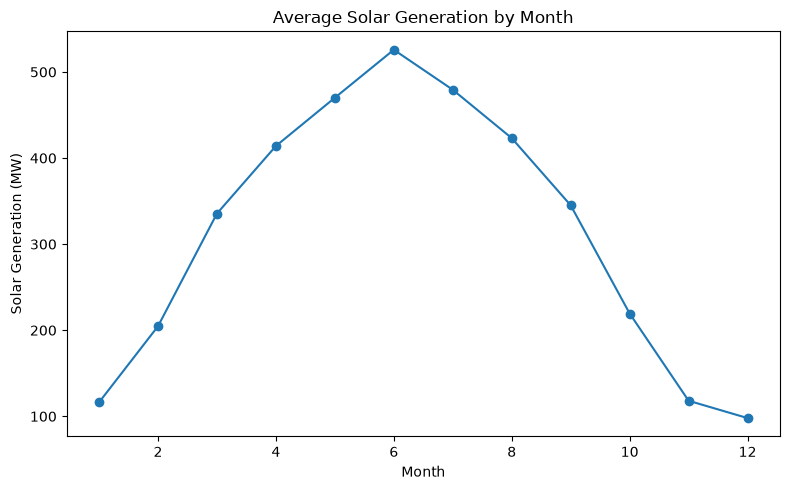

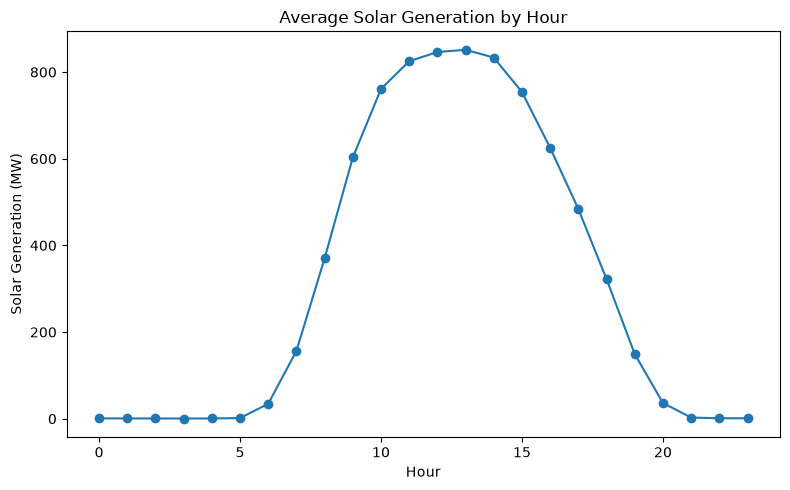

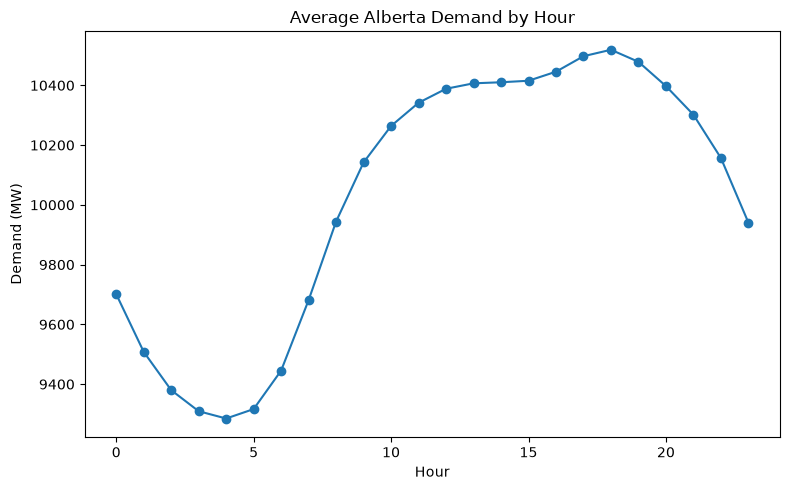

In [ ]:
monthly_solar = (
    train.groupby("Month")["SOLAR"]
    .mean()
)

plt.figure(figsize=(8,5))
monthly_solar.plot(marker="o")
plt.title("Average Solar Generation by Month")
plt.ylabel("Solar Generation (MW)")
plt.tight_layout()
plt.show()

hourly_solar = (
    train.groupby("Hour")["SOLAR"]
    .mean()
)

plt.figure(figsize=(8,5))
hourly_solar.plot(marker="o")
plt.title("Average Solar Generation by Hour")
plt.ylabel("Solar Generation (MW)")
plt.tight_layout()
plt.show()

hourly_demand = (
    train.groupby("Hour")["ALL Demand (MW)"]
    .mean()
)

plt.figure(figsize=(8,5))
hourly_demand.plot(marker="o")
plt.title("Average Alberta Demand by Hour")
plt.ylabel("Demand (MW)")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# FEATURES
# ============================================================

features = [
    "Weekday",
    "Year",
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "DaylightFraction"
]

# ============================================================
# TARGETS
# ============================================================

targets = {
    "Solar Generation": "SOLAR",
    "Demand": "ALL Demand (MW)"
}


In [ ]:
# ============================================================
# PREPROCESSOR
# ============================================================

categorical_features = [
    "Weekday"
]

numeric_features = [
    "Year",
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "DaylightFraction"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "weekday",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)



In [ ]:
# ============================================================
# MODEL LOOP
# ============================================================

results = []

for model_name, target in targets.items():

    print(f"\nRunning {model_name}")

    train_model = train.dropna(
        subset=features + [target]
    )

    test_model = test.dropna(
        subset=features + [target]
    )

    X_train = train_model[features]
    y_train = train_model[target]

    X_test = test_model[features]
    y_test = test_model[target]

    pipeline = Pipeline(
        [
            ("prep", preprocessor),
            ("ridge", Ridge())
        ]
    )

    param_grid = {
        "ridge__alpha": [
            0.01,
            0.1,
            1,
            10,
            100,
            1000
        ]
    }

    model = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        cv=5,
        scoring="r2",
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    best_alpha = (
        model.best_params_["ridge__alpha"]
    )

    train_r2 = r2_score(
        y_train,
        train_pred
    )

    test_r2 = r2_score(
        y_test,
        test_pred
    )

    train_mae = mean_absolute_error(
        y_train,
        train_pred
    )

    test_mae = mean_absolute_error(
        y_test,
        test_pred
    )

    train_rmse = np.sqrt(
        mean_squared_error(
            y_train,
            train_pred
        )
    )

    test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            test_pred
        )
    )

    print(f"Best Alpha: {best_alpha}")
    print(f"Train R² : {train_r2:.4f}")
    print(f"Test  R² : {test_r2:.4f}")


Running Solar Generation


Best Alpha: 10
Train R² : 0.8148
Test  R² : 0.7816

Running Demand
Best Alpha: 100
Train R² : 0.6187
Test  R² : 0.5954


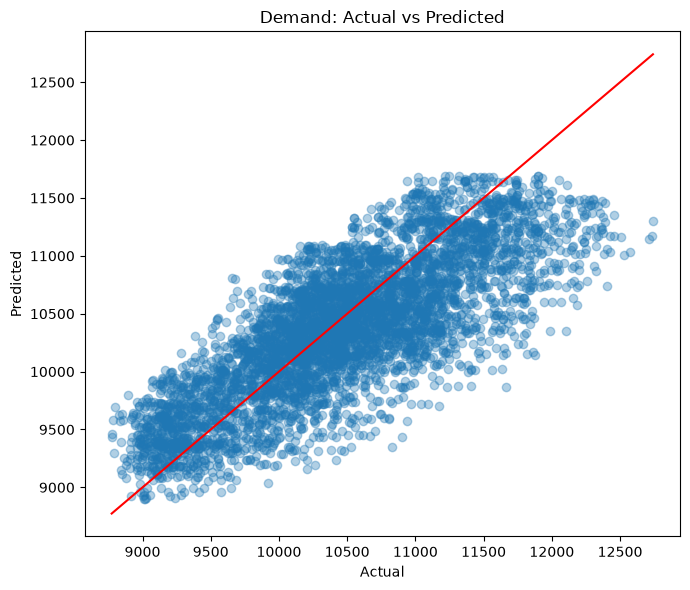

In [ ]:
    # ========================================================
    # ACTUAL VS PREDICTED
    # ========================================================

sample_size = min(
        5000,
        len(test_model)
    )

sample_idx = np.random.choice(
        len(test_model),
        sample_size,
        replace=False
    )

actual_sample = y_test.iloc[sample_idx]
predicted_sample = test_pred[sample_idx]

plt.figure(figsize=(7,6))

plt.scatter(
        actual_sample,
        predicted_sample,
        alpha=0.35
    )

min_val = min(
        actual_sample.min(),
        predicted_sample.min()
    )

max_val = max(
        actual_sample.max(),
        predicted_sample.max()
    )

plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="red"
    )

plt.xlabel("Actual")
plt.ylabel("Predicted")

plt.title(
        f"{model_name}: Actual vs Predicted"
    )

plt.tight_layout()

plt.show()

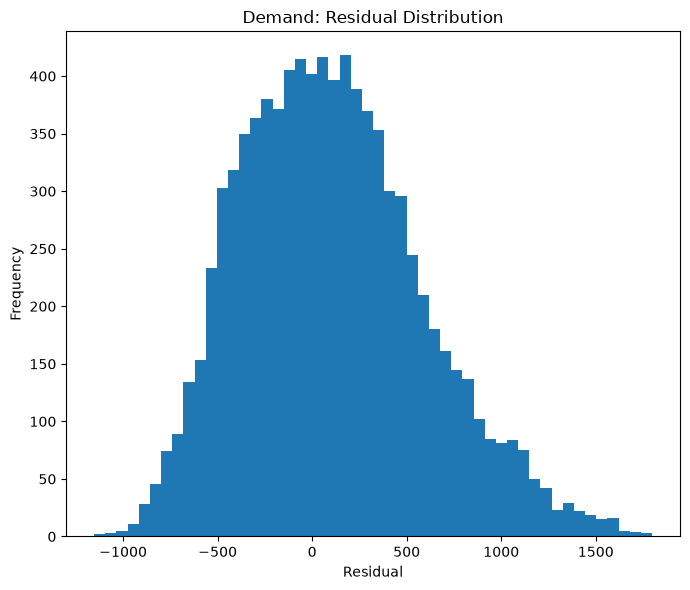

In [ ]:
    # ========================================================
    # RESIDUALS
    # ========================================================

    residuals = (
        y_test - test_pred
    )

    plt.figure(figsize=(7,6))

    plt.hist(
        residuals,
        bins=50
    )

    plt.xlabel("Residual")
    plt.ylabel("Frequency")

    plt.title(
        f"{model_name}: Residual Distribution"
    )

    plt.tight_layout()

    plt.show()

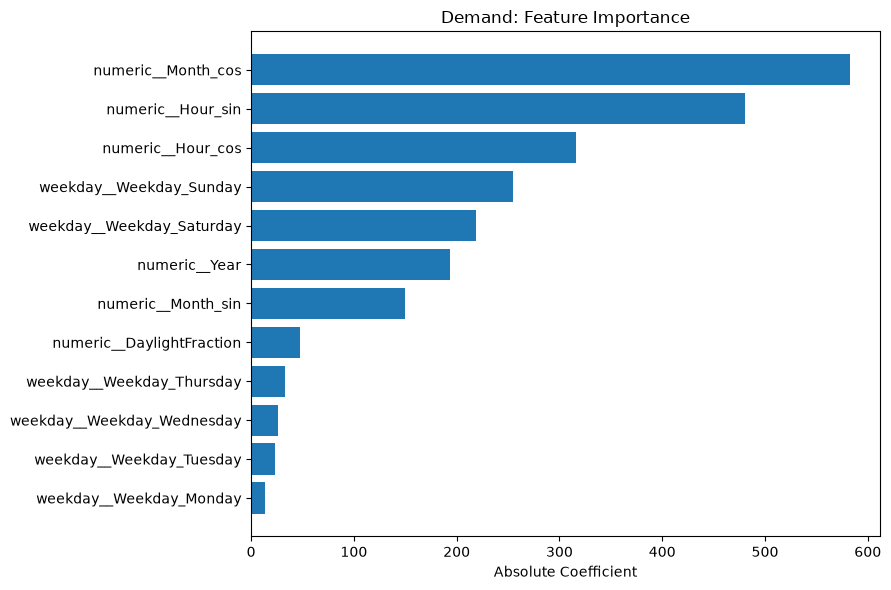

In [ ]:
    # ========================================================
    # FEATURE IMPORTANCE
    # ========================================================

    best_pipeline = model.best_estimator_

    ridge = (
        best_pipeline
        .named_steps["ridge"]
    )

    feature_names = (
        best_pipeline
        .named_steps["prep"]
        .get_feature_names_out()
    )

    coeff_df = pd.DataFrame(
        {
            "Feature": feature_names,
            "Coefficient": ridge.coef_
        }
    )

    coeff_df["Importance"] = (
        coeff_df["Coefficient"].abs()
    )

    coeff_df = coeff_df.sort_values(
        "Importance",
        ascending=False
    )

    coeff_df.to_csv(
        f"{model_name}_coefficients.csv",
        index=False
    )

    top = coeff_df.head(15)

    plt.figure(figsize=(9,6))

    plt.barh(
        top["Feature"],
        top["Importance"]
    )

    plt.gca().invert_yaxis()

    plt.xlabel(
        "Absolute Coefficient"
    )

    plt.title(
        f"{model_name}: Feature Importance"
    )

    plt.tight_layout()

    plt.show()

    results.append([
        model_name,
        best_alpha,
        train_r2,
        test_r2,
        train_r2 - test_r2,
        train_mae,
        test_mae,
        train_rmse,
        test_rmse
    ])

In [ ]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Best Alpha",
        "Train R2",
        "Test R2",
        "R2 Gap",
        "Train MAE",
        "Test MAE",
        "Train RMSE",
        "Test RMSE"
    ]
)

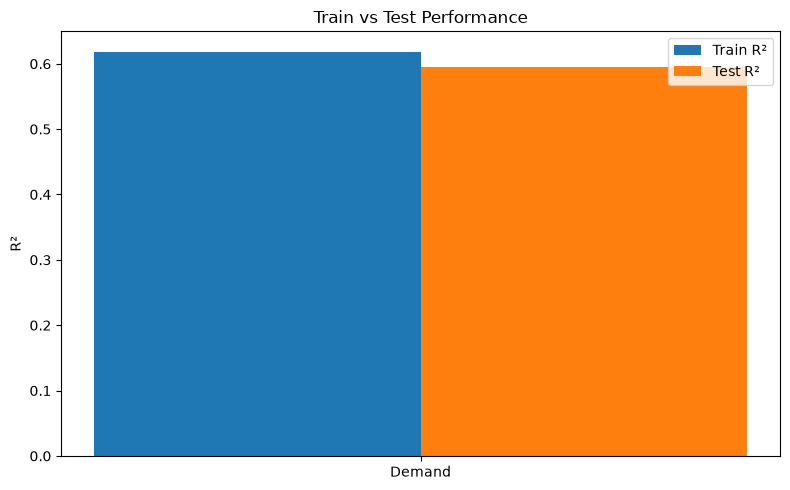

In [ ]:

# ============================================================
# R2 COMPARISON PLOT
# ============================================================

plt.figure(figsize=(8,5))

x = np.arange(
    len(results_df)
)

width = 0.35

plt.bar(
    x - width/2,
    results_df["Train R2"],
    width,
    label="Train R²"
)

plt.bar(
    x + width/2,
    results_df["Test R2"],
    width,
    label="Test R²"
)

plt.xticks(
    x,
    results_df["Model"]
)

plt.ylabel("R²")

plt.title(
    "Train vs Test Performance"
)

plt.legend()

plt.tight_layout()

plt.show()